noise=0.5  | Intercept=4.10 | Slope=3.00 | MSE=0.229 | R2=0.888
noise=1    | Intercept=4.11 | Slope=2.76 | MSE=1.597 | R2=0.557
noise=2    | Intercept=4.23 | Slope=2.56 | MSE=4.537 | R2=0.481
noise=5    | Intercept=4.37 | Slope=2.26 | MSE=30.354 | R2=0.196
noise=10   | Intercept=3.46 | Slope=2.82 | MSE=71.768 | R2=-0.138


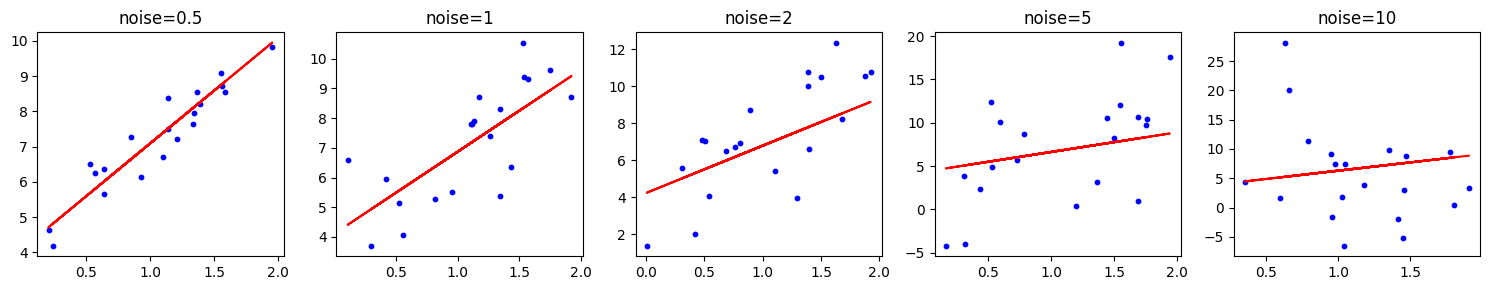

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(0)

# Các mức nhiễu cần thử: từ ít đến rất nhiều
cac_muc_nhieu = [0.5, 1, 2, 5, 10]
ket_qua = []   # lưu (noise, mse, r2) để nhận xét

plt.figure(figsize=(15, 3))
for i, noise in enumerate(cac_muc_nhieu):
    # Sinh dữ liệu: y = 4 + 3x + nhiễu (giống ví dụ đề cương)
    # noise càng lớn thì các điểm càng phân tán xa đường thẳng thật
    x = 2 * np.random.rand(100, 1)
    y = 4 + 3 * x + noise * np.random.randn(100, 1)

    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    ket_qua.append((noise, mse, r2))

    print(f"noise={noise:<4} | Intercept={model.intercept_[0]:.2f} | "
          f"Slope={model.coef_[0][0]:.2f} | MSE={mse:.3f} | R2={r2:.3f}")

    # Vẽ mỗi mức nhiễu một biểu đồ nhỏ
    plt.subplot(1, len(cac_muc_nhieu), i + 1)
    plt.scatter(x_test, y_test, color="blue", s=10)
    plt.plot(x_test, y_pred, color="red")
    plt.title(f"noise={noise}")
plt.tight_layout()
plt.show()

# NHẬN XÉT:
# - Noise tăng -> MSE tăng mạnh (xấp xỉ noise^2), R2 giảm dần về gần 0.
# - Intercept/Slope ước lượng lệch xa giá trị thật (4 và 3) khi nhiễu lớn.
# - Mô hình vẫn là đường thẳng, nhưng dữ liệu quá nhiễu nên dự đoán kém tin cậy.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(0)

# --- Dữ liệu BMI -> Mắc bệnh (giống bài 2 ở lớp) ---
n = 300
bmi = np.clip(np.random.normal(25, 5, n), 15, 40)
xac_suat = 1 / (1 + np.exp(-(bmi - 27) * 0.5))
mac_benh = (np.random.rand(n) < xac_suat).astype(int)
X, y = bmi.reshape(-1, 1), mac_benh

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LogisticRegression().fit(X_train, y_train)

# Lấy xác suất lớp 1 MỘT LẦN, sau đó tự áp ngưỡng khác nhau
y_proba = model.predict_proba(X_test)[:, 1]

for nguong in [0.3, 0.5, 0.6, 0.7, 0.8, 0.9]:
    # Nếu xác suất >= ngưỡng thì dự đoán 1 (mắc bệnh), ngược lại 0
    y_pred = (y_proba >= nguong).astype(int)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print(f"Ngưỡng {nguong}: Accuracy={accuracy_score(y_test, y_pred):.3f} | "
          f"TN={tn}, FP={fp}, FN={fn}, TP={tp} | số ca dự đoán bệnh={y_pred.sum()}")

# NHẬN XÉT:
# - Ngưỡng tăng -> mô hình "khó tính" hơn, dự đoán ít ca bệnh hơn
#   -> FP giảm (ít báo nhầm) nhưng FN tăng (bỏ sót ca bệnh thật).
# - Ngưỡng giảm -> ngược lại: bắt được nhiều ca bệnh hơn nhưng báo nhầm nhiều hơn.
# - Accuracy thường cao nhất quanh 0.5; với bài toán bệnh, bỏ sót ca bệnh (FN)
#   nguy hiểm hơn nên có thể chọn ngưỡng thấp hơn 0.5.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# ---------------------------------------------------------
# 1. Tải tập dữ liệu giá nhà
# ---------------------------------------------------------
data = fetch_california_housing(as_frame=True)
df = data.frame
print("Kích thước:", df.shape)
print(df.head())
# Cột MedHouseVal là giá nhà trung vị (đơn vị 100.000 USD) -> biến đầu ra
# Các cột còn lại (MedInc, HouseAge, AveRooms, ...) là biến đầu vào

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

# ---------------------------------------------------------
# 2. Phân chia dữ liệu thành tập huấn luyện và tập kiểm tra (80/20)
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------------
# 3. Huấn luyện mô hình trên tập train, dự đoán trên tập test
# ---------------------------------------------------------
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# ---------------------------------------------------------
# 4. Tính MSE và R2 trên tập kiểm tra
# ---------------------------------------------------------
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_}")
print("Hệ số hồi quy (Coefficients):")
print(pd.Series(model.coef_, index=X.columns))
print(f"Mean Squared Error (MSE): {mse}")   # khoảng 0.55
print(f"R^2 score: {r2}")                   # khoảng 0.58

# Biểu đồ giá thực và giá dự đoán (điểm càng gần đường đỏ càng chính xác)
plt.scatter(y_test, y_pred, alpha=0.3, color="blue", label="Dự đoán")
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", label="Dự đoán hoàn hảo (y = x)")
plt.title("Giá nhà thực và giá nhà dự đoán")
plt.xlabel("Giá thực")
plt.ylabel("Giá dự đoán")
plt.legend()
plt.show()

# NHẬN XÉT:
# - R2 khoảng 0.58: mô hình giải thích được ~58% sự biến thiên của giá nhà.
# - MedInc (thu nhập trung vị) có hệ số dương lớn nhất -> ảnh hưởng mạnh nhất đến giá.
# - Giá bị chặn trần ở 5.0 nên các điểm xếp thành một dải ngang ở trên cùng biểu đồ.